# 02 · Forecast backtest

Every model is scored on the same 13-week holdout. WAPE is the headline metric (volume-weighted, robust to small weeks); bias shows systematic over/under-forecasting.

In [1]:
import os
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# works whether the notebook is run from the repo root or from notebooks/
root = Path.cwd() if (Path.cwd() / "pharmapulse").exists() else Path.cwd().parent
os.environ["PHARMAPULSE_DB"] = str(root / "data" / "pharmapulse.duckdb")
pd.set_option("display.width", 140)
COLORS = {"Glyvance": "#2a78d6", "Sitaglin": "#eb6834", "Dapaflo": "#1baf7a", "Glucora": "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "figure.figsize": (10, 4)})

In [2]:
from pharmapulse.analytics import forecasting as fc
bt = pd.concat([fc.backtest(b) for b in COLORS])
bt.pivot(index='brand', columns='model', values='wape').round(3)

model,ets,gbm,seasonal_naive
brand,,,
Dapaflo,0.013,0.032,0.040
Glucora,0.035,0.080,0.062
Glyvance,0.040,0.091,0.090
Sitaglin,0.036,0.026,0.056


In [3]:
bt.groupby('model')[['wape', 'mape', 'bias']].mean().round(3)

,wape,mape,bias
model,,,
ets,0.031,0.031,-0.007
gbm,0.057,0.057,-0.050
seasonal_naive,0.062,0.062,-0.061


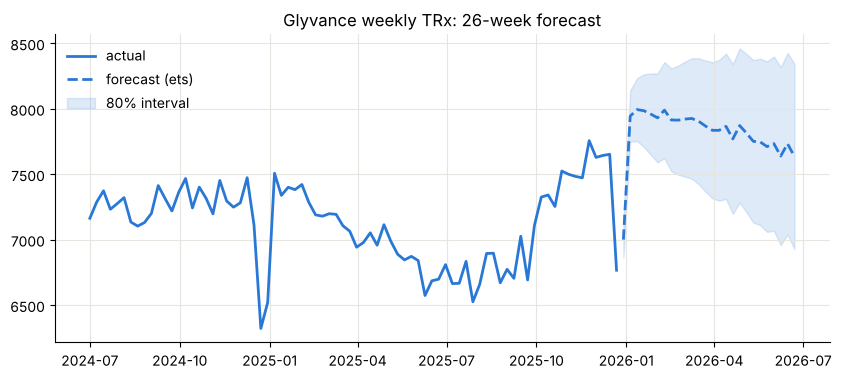

203212.0

In [4]:
f = fc.forecast('Glyvance', 26)
h = f.history.iloc[-78:]
fig, ax = plt.subplots()
ax.plot(h.index, h.values, color=COLORS['Glyvance'], lw=2, label='actual')
ax.plot(f.forecast['week'], f.forecast['yhat'], '--', color=COLORS['Glyvance'], lw=2,
        label=f'forecast ({f.model})')
ax.fill_between(f.forecast['week'], f.forecast['lower'], f.forecast['upper'],
                color=COLORS['Glyvance'], alpha=0.15, label='80% interval')
ax.set_title('Glyvance weekly TRx: 26-week forecast'); ax.legend(frameon=False); plt.show()
f.to_dict()['total_forecast']

## Promotional response

Adstocked call elasticity from a HCP-month panel with HCP potential and month fixed effects. Observational, so it's an association, not a causal effect.

In [5]:
from pharmapulse.analytics import promo_response as pr
pd.DataFrame([pr.fit(d).to_dict() for d in (0.3, 0.5, 0.7)])[['decay','elasticity','ci_low','ci_high','incremental_nrx_per_100_calls','r_squared']]

,decay,elasticity,ci_low,ci_high,incremental_nrx_per_100_calls,r_squared
0,0.3,0.0534,0.0468,0.0601,17.2257,0.6700
1,0.5,0.0474,0.0406,0.0542,16.8063,0.6697
2,0.7,0.0321,0.0251,0.0391,13.2133,0.6692
